# a sanity check on an air layer to account for flight height

In [1]:
import torch

from em1d.experiment import Loop, Receiver, Forward
import matplotlib.pyplot as plt
import numpy as np

C:\Users\au646858\AppData\Local\Temp\ipykernel_17104\3122067600.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  sigma = torch.tensor(sigma)
C:\Users\au646858\AppData\Local\Temp\ipykernel_17104\3122067600.py:10: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  thick = torch.tensor(thick)
c:\users\au646858\onedrive - aarhus universitet\documents\repositories\em1d\src\em1d\experiment\experiment.py:236: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.sigma = torch.tensor(sigma, dtype=torch.complex128)[...,None,None]
c:\users\au646858\oned

10 forwards: 0.36340689999997267


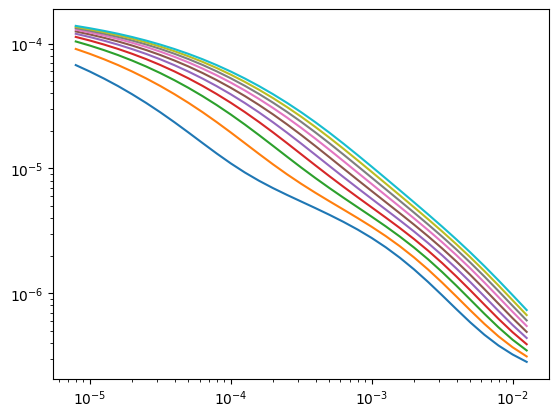

In [13]:
lp = Loop.circle(6, z=20)
rx = Receiver(z=25)
times = np.logspace(-5,-2, 31)

nf = 10
sigma = torch.tensor([0.1, 1, 0.1, 0.3, 10, 25, 0.2, 0.5, 10, 15, 20])[:,None] + torch.tensor(np.arange(nf)*0.1)[None,:]
thick = torch.tensor([40, 40, 40, 40, 40, 40, 40, 40, 40, 40])[:,None] + torch.tensor(np.arange(nf)*0.1)[None,:]

sigma = torch.tensor(sigma)
thick = torch.tensor(thick)

fwr = Forward(lp, rx, times)
from time import perf_counter as timer
bt = timer()
t1,dbdt1 = fwr(sigma, thick)
print(f'{nf} forwards: {timer()-bt}')

# Plot sounding
fig,ax = plt.subplots()
ax.loglog(t1.numpy(), np.abs(dbdt1.numpy().real), label='normal_setup')

In [21]:
n_forwards = np.logspace(0, 3, 16).astype(int)
t_forwards = np.zeros(n_forwards.shape)

from time import perf_counter as timer

for i_nf,nf in enumerate(n_forwards):
    sigma = torch.tensor([0.1, 1, 0.1, 0.3, 10, 25, 0.2, 0.5, 10, 15, 20])[:,None] + torch.tensor(np.arange(nf)*0.1)[None,:]
    thick = torch.tensor([40, 40, 40, 40, 40, 40, 40, 40, 40, 40])[:,None] + torch.tensor(np.arange(nf)*0.1)[None,:]

    fwr = Forward(lp, rx, times)
    bt = timer()
    for i in range(5):
        t1,dbdt1 = fwr(sigma, thick)
    t_forwards[i_nf] = (timer()-bt)/5
    print(nf)

c:\users\au646858\onedrive - aarhus universitet\documents\repositories\em1d\src\em1d\experiment\experiment.py:236: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.sigma = torch.tensor(sigma, dtype=torch.complex128)[...,None,None]
c:\users\au646858\onedrive - aarhus universitet\documents\repositories\em1d\src\em1d\experiment\experiment.py:237: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.thick = torch.tensor(thickness, dtype=torch.complex128)[...,None,None]


1
1
2
3
6
10
15
25
39
63
100
158
251
398
630
1000


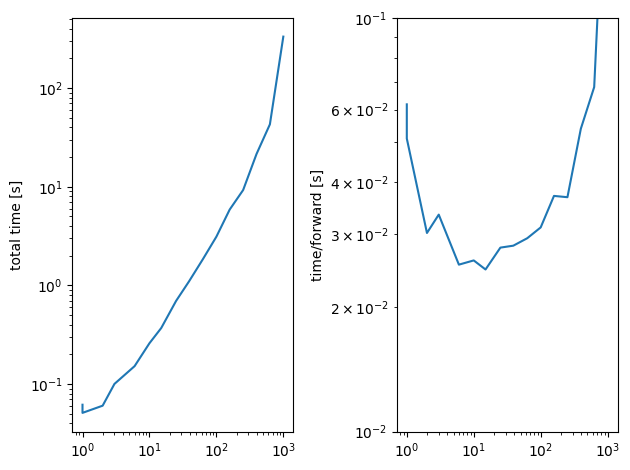

In [22]:
fig,axs = plt.subplots(1,2)
axs[0].loglog(n_forwards, t_forwards);            axs[0].set_ylabel('total time [s]')
axs[1].loglog(n_forwards, t_forwards/n_forwards); axs[1].set_ylabel('time/forward [s]')
axs[1].set_ylim(0.01, 0.1)
plt.tight_layout()

so appears to be at the machine precision level so that is wonderful.